# Блокнот 03: Географічна типізація та ієрархічна кластеризація (RQ2)

**Дослідницьке питання (RQ2):**
> *Як принципово відрізняються профілі загроз для різних регіонів (глибокий тил на зразок Закарпаття, транзитний центр на зразок Київщини, прифронтові східні та південні області), і на яку оптимальну кількість кластерів $K$ ділиться безпекова карта України на основі дендрограми та метрик якості кластеризації (Silhouette Score, Davies-Bouldin)?*

У цьому блокноті реалізовано:
1. Побудову 5-вимірного цифрового паспорта для 24 регіонів України.
2. Z-стандартизацію ознак через `StandardScaler`.
3. Пошук оптимального $K \in [2, 6]$ за метриками Silhouette Score та Davies-Bouldin Index.
4. Ієрархічну агломеративну кластеризацію за методом Варда (Ward linkage).
5. Візуалізацію дендрограми та аналіз відмінностей між отриманими кластерами.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Завантажуємо зведену таблицю профілів кластеризації
summary_path = Path("../reports/official/regional_clusters_summary.csv")
profiles_df = pd.read_csv(summary_path, index_col="oblast")
print(f"Завантажено профілі для {len(profiles_df)} регіонів України.")
display(profiles_df.head())

Завантажено профілі для 24 регіонів України.


,total_alerts,alerts_per_month,median_duration_min,mean_duration_min,night_ratio,short_ratio,long_ratio,cluster,cluster_name
oblast,,,,,,,,,
Івано-Франківська область,839,15.641504,44.300000,65.573023,0.258641,0.313468,0.139452,1,Глибокий тил (Захід)
Волинська область,933,17.393949,42.516667,64.288353,0.236870,0.344051,0.133976,1,Глибокий тил (Захід)
Вінницька область,1810,33.743888,44.900000,79.613895,0.309392,0.328729,0.207735,1,Глибокий тил (Захід)
Дніпропетровська область,5403,100.728301,33.550000,165.317077,0.197483,0.390894,0.108828,2,Транзитний центр / Північ
Донецька область,7218,134.565403,61.883333,162.391521,0.190219,0.222776,0.316431,3,Прифронтова / Прикордонна зона


## 1. Математичне обґрунтування вибору кількості кластерів (K)

Ми не фіксуємо кількість кластерів наосліп. Перебір $K \in [2, 6]$ оцінюється за двома незалежними метриками якості:
- **Silhouette Score (Коефіцієнт силуету):** показує якість відокремленості кластерів (максимізуємо).
- **Davies-Bouldin Index:** відношення внутрішньокластерного розсіювання до міжкластерної відстані (мінімізуємо).

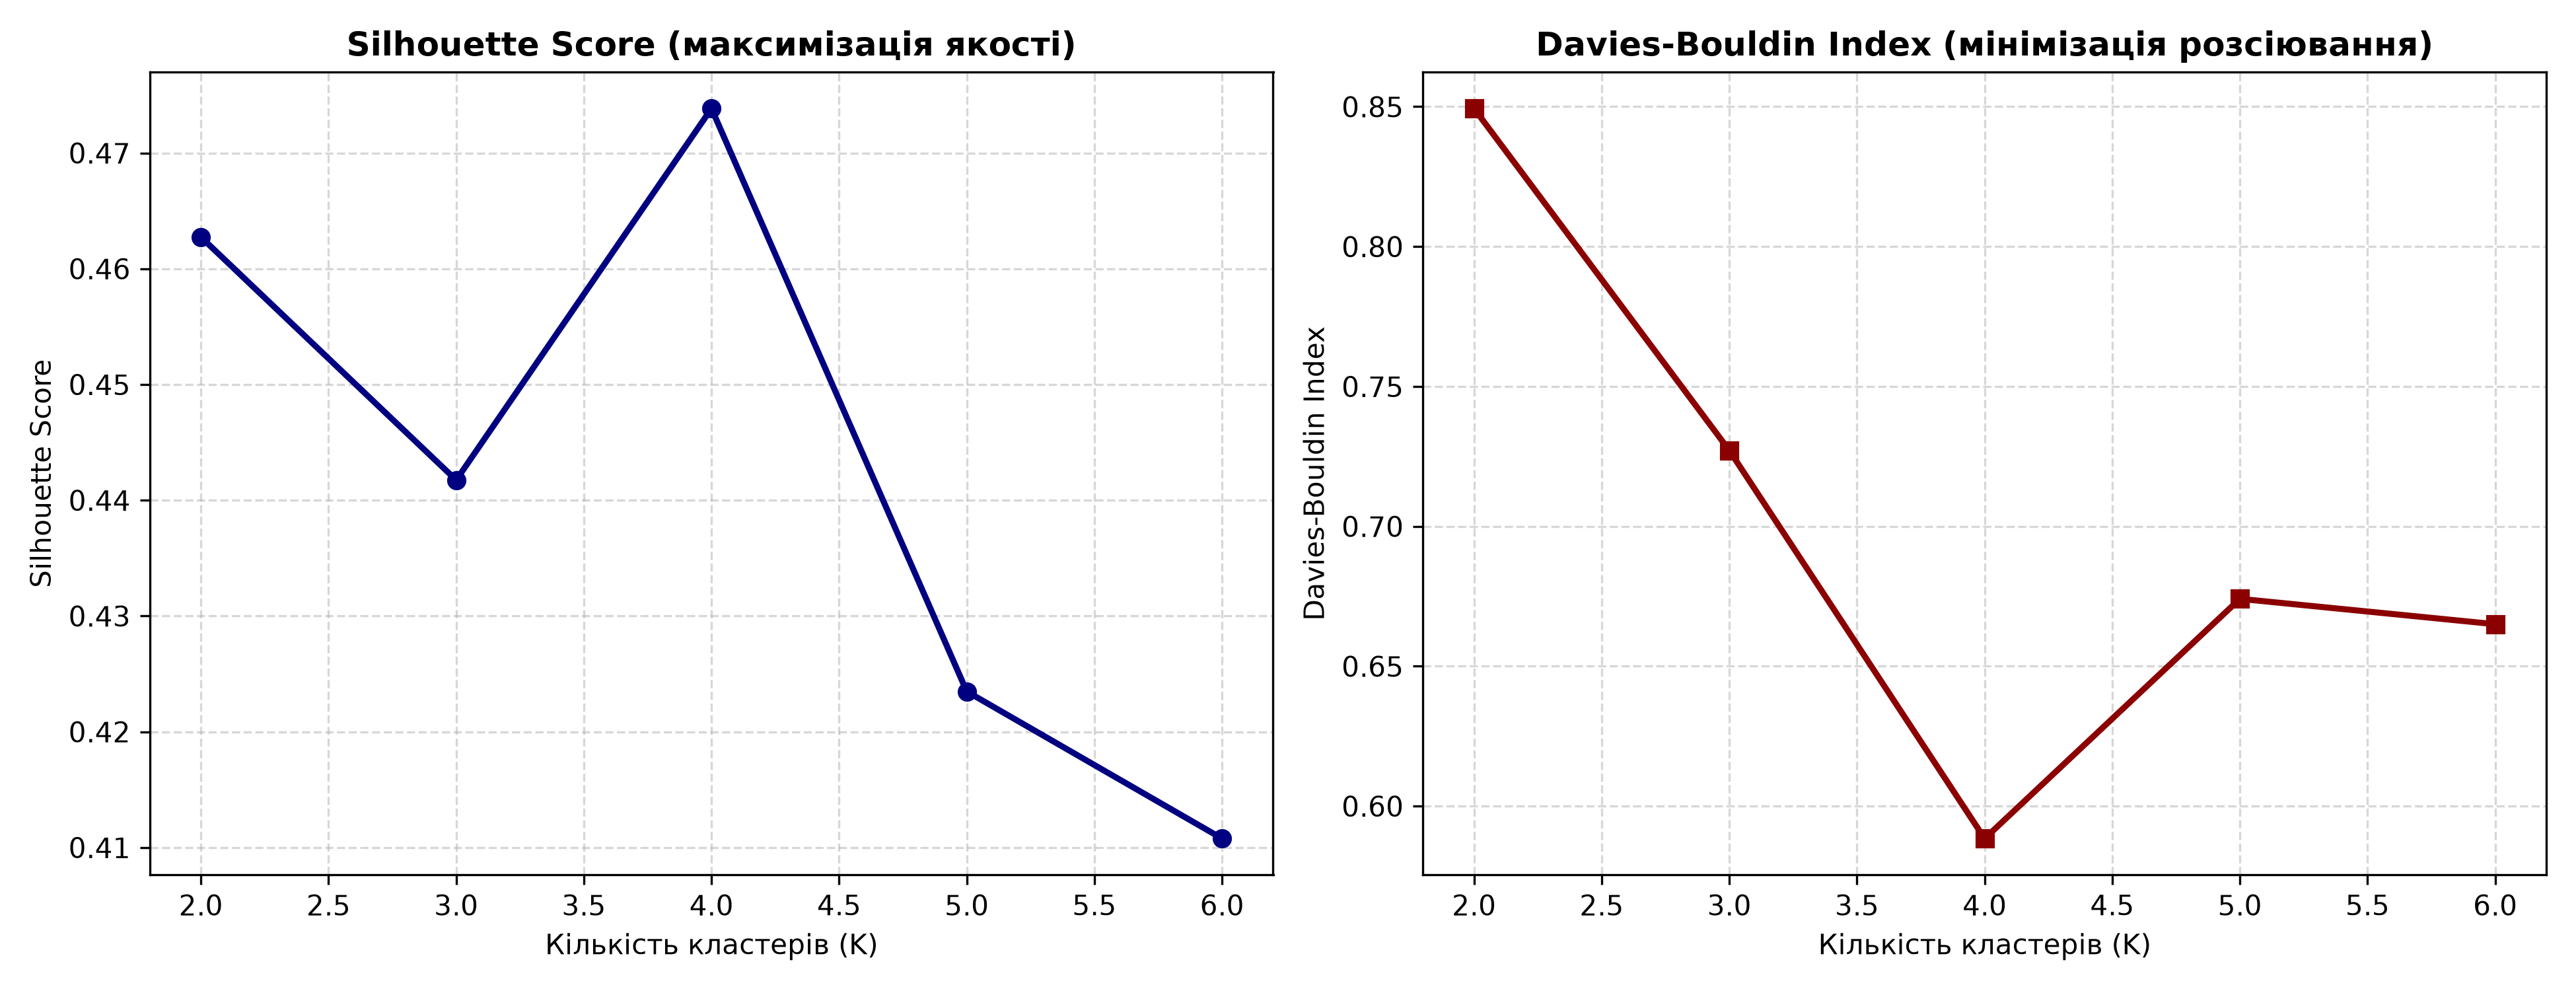

In [2]:
display(Image("../reports/official/figures/04_clustering_metrics_evaluation.png"))

## 2. Ієрархічна дендрограма зв'язків між областями (Ward Linkage)

Дендрограма наочно відображає «генеалогічне дерево» схожості областей України за характером загроз.

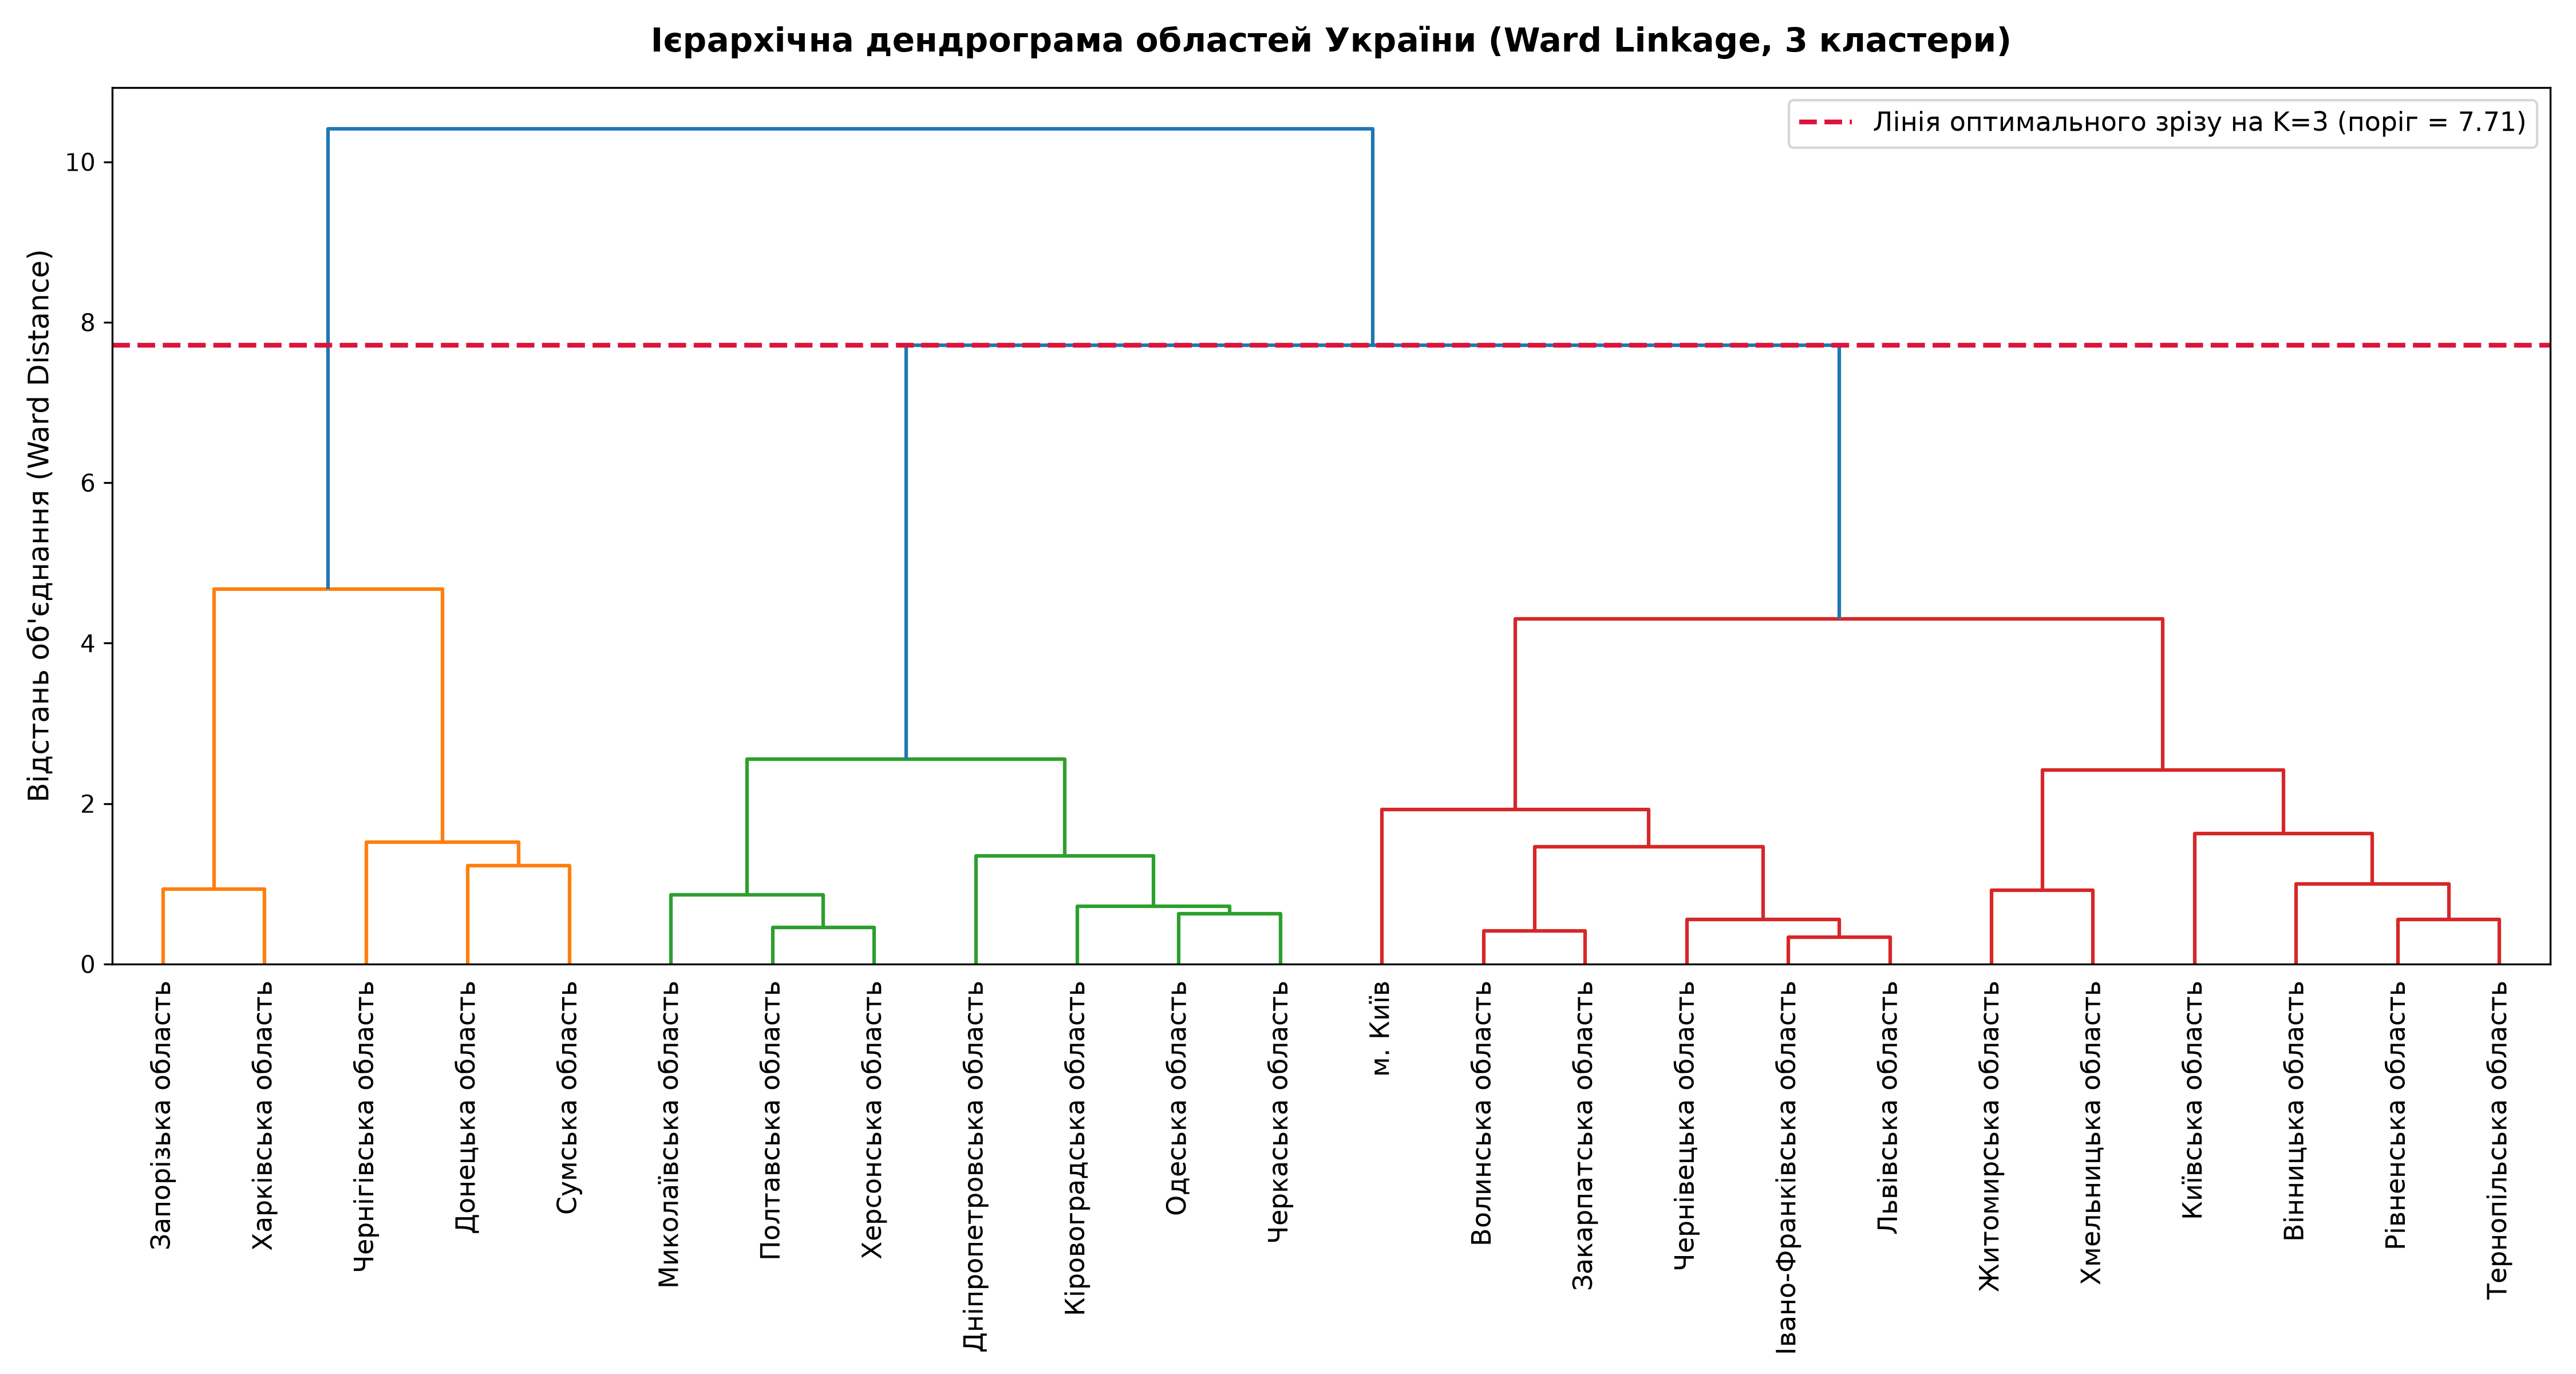

In [3]:
display(Image("../reports/official/figures/05_regional_dendrogram.png"))

## 3. Зведена аналітична характеристика виділених кластерів

In [4]:
cluster_summary = profiles_df.groupby("cluster_name")[
    ["alerts_per_month", "median_duration_min", "night_ratio", "short_ratio", "long_ratio"]
].mean()

# Переводимо частки у відсотки для наочності
cluster_summary["night_ratio_%"] = cluster_summary["night_ratio"] * 100
cluster_summary["short_ratio_%"] = cluster_summary["short_ratio"] * 100
cluster_summary["long_ratio_%"] = cluster_summary["long_ratio"] * 100
display(cluster_summary[["alerts_per_month", "median_duration_min", "night_ratio_%", "short_ratio_%", "long_ratio_%"]])

,alerts_per_month,median_duration_min,night_ratio_%,short_ratio_%,long_ratio_%
cluster_name,,,,,
Глибокий тил (Захід),25.795742,46.431250,27.704810,32.170283,17.417511
Прифронтова / Прикордонна зона,128.282702,57.345000,19.024413,25.219203,28.726409
Транзитний центр / Північ,90.280213,36.014286,21.286436,38.324017,14.174470


## 4. Склад кожного кластера

In [5]:
for c_name, group in profiles_df.groupby("cluster_name"):
    print(f"\n📍 {c_name.upper()} ({len(group)} областей):")
    print(", ".join(sorted(group.index.tolist())))
    print(f"Середня кількість тривог на місяць: {group['alerts_per_month'].mean():.1f}")


📍 ГЛИБОКИЙ ТИЛ (ЗАХІД) (12 областей):
Івано-Франківська область, Волинська область, Вінницька область, Житомирська область, Закарпатська область, Київська область, Львівська область, Рівненська область, Тернопільська область, Хмельницька область, Чернівецька область, м. Київ
Середня кількість тривог на місяць: 25.8

📍 ПРИФРОНТОВА / ПРИКОРДОННА ЗОНА (5 областей):
Донецька область, Запорізька область, Сумська область, Харківська область, Чернігівська область
Середня кількість тривог на місяць: 128.3

📍 ТРАНЗИТНИЙ ЦЕНТР / ПІВНІЧ (7 областей):
Дніпропетровська область, Кіровоградська область, Миколаївська область, Одеська область, Полтавська область, Херсонська область, Черкаська область
Середня кількість тривог на місяць: 90.3
